# Data Science Fundamentals - Completed Assignments
Covers Python basics, data types, NumPy and pandas, statistical foundations, and industry best practices.
Every cell below was run top to bottom with fixed random seeds, so the outputs are reproducible.

- Assignment 1: Python basics
- Assignment 2: Data types
- Assignment 3: NumPy and pandas
- Assignment 4: Statistical foundations
- Assignment 5: Industry best practices

## Assignment 1 - Python basics
**Task 1.1** Write `fizzbuzz(n)` returning "Fizz" for multiples of 3, "Buzz" for multiples of 5, "FizzBuzz" for both, otherwise the number. Apply it to 1..20.

In [1]:
def fizzbuzz(n):
    """Return the FizzBuzz label for n."""
    if n % 15 == 0:
        return "FizzBuzz"
    if n % 3 == 0:
        return "Fizz"
    if n % 5 == 0:
        return "Buzz"
    return n

print([fizzbuzz(i) for i in range(1, 21)])
assert fizzbuzz(15) == "FizzBuzz" and fizzbuzz(9) == "Fizz" and fizzbuzz(10) == "Buzz" and fizzbuzz(7) == 7

[1, 2, 'Fizz', 4, 'Buzz', 'Fizz', 7, 8, 'Fizz', 'Buzz', 11, 'Fizz', 13, 14, 'FizzBuzz', 16, 17, 'Fizz', 19, 'Buzz']


**Task 1.2** Count word frequencies in a sentence twice: with a plain dictionary and with `collections.Counter`. Confirm both agree.

In [2]:
from collections import Counter

text = "data science is fun and data science is useful"
words = text.split()

manual = {}
for w in words:
    manual[w] = manual.get(w, 0) + 1

freq = Counter(words)
print(freq.most_common(3))
assert manual == dict(freq)

[('data', 2), ('science', 2), ('is', 2)]


**Task 1.3** Implement mean, median, mode and sample standard deviation from scratch and check them against the `statistics` module.

In [3]:
import statistics

def mean(xs):
    return sum(xs) / len(xs)

def median(xs):
    s = sorted(xs)
    n, mid = len(s), len(s) // 2
    return s[mid] if n % 2 else (s[mid - 1] + s[mid]) / 2

def mode(xs):
    counts = Counter(xs)
    top = max(counts.values())
    return sorted(k for k, v in counts.items() if v == top)

def std(xs, sample=True):
    m = mean(xs)
    denom = len(xs) - 1 if sample else len(xs)
    return (sum((x - m) ** 2 for x in xs) / denom) ** 0.5

data = [4, 8, 6, 5, 3, 8, 9, 5, 8]
print("mean  :", round(mean(data), 4))
print("median:", median(data))
print("mode  :", mode(data))
print("std   :", round(std(data), 4))

assert abs(mean(data) - statistics.mean(data)) < 1e-9
assert median(data) == statistics.median(data)
assert mode(data) == statistics.multimode(data)
assert abs(std(data) - statistics.stdev(data)) < 1e-9

mean  : 6.2222
median: 6
mode  : [8]
std   : 2.1082


**Task 1.4** Use a list comprehension and a dictionary comprehension: the even numbers up to 20, and a mapping of n to n squared for 1..5.

In [4]:
evens = [n for n in range(1, 21) if n % 2 == 0]
squares = {n: n ** 2 for n in range(1, 6)}
print(evens)
print(squares)
assert len(evens) == 10 and squares[5] == 25

[2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
{1: 1, 2: 4, 3: 9, 4: 16, 5: 25}


**Task 1.5** Write `safe_divide(a, b)` that returns NaN on division by zero and raises a clear `ValueError` for non-numeric input.

In [5]:
import math

def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        return float("nan")
    except TypeError:
        raise ValueError("safe_divide needs two numbers")

print(safe_divide(10, 4))
print(safe_divide(1, 0))
try:
    safe_divide("a", 2)
except ValueError as e:
    print("ValueError:", e)

assert safe_divide(10, 4) == 2.5 and math.isnan(safe_divide(1, 0))

2.5
nan
ValueError: safe_divide needs two numbers


## Assignment 2 - Data types
**Task 2.1** Classify common variables by category, kind and measurement scale.

In [6]:
import pandas as pd
import numpy as np

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 20)

variables = pd.DataFrame(
    [
        ("Customer rating (1-5)",   "Categorical", "Ordinal",    "Ordinal"),
        ("Temperature in Celsius",  "Numerical",   "Continuous", "Interval"),
        ("City name",               "Categorical", "Nominal",    "Nominal"),
        ("Number of purchases",     "Numerical",   "Discrete",   "Ratio"),
        ("Annual income",           "Numerical",   "Continuous", "Ratio"),
        ("Payment method",          "Categorical", "Nominal",    "Nominal"),
    ],
    columns=["variable", "category", "kind", "scale"],
)
print(variables.to_string(index=False))
assert len(variables) == 6

              variable    category       kind    scale
 Customer rating (1-5) Categorical    Ordinal  Ordinal
Temperature in Celsius   Numerical Continuous Interval
             City name Categorical    Nominal  Nominal
   Number of purchases   Numerical   Discrete    Ratio
         Annual income   Numerical Continuous    Ratio
        Payment method Categorical    Nominal  Nominal


**Task 2.2** A raw customer table arrives with every column stored as text. Convert each column to the correct type and handle bad values safely.

In [7]:
raw = pd.DataFrame({
    "customer_id": ["101", "102", "103", "104"],
    "age":         ["29", "41", "n/a", "35"],
    "signup_date": ["2024-01-15", "2024-02-20", "2024-03-05", "not a date"],
    "plan":        ["basic", "premium", "basic", "premium"],
    "spend":       ["1,200.50", "980", "1,050.25", "450"],
})
print("BEFORE")
print(raw.dtypes.astype(str).to_string())

customers = raw.copy()
customers["customer_id"] = customers["customer_id"].astype("int64")
customers["age"] = pd.to_numeric(customers["age"], errors="coerce")
customers["signup_date"] = pd.to_datetime(customers["signup_date"], errors="coerce")
customers["plan"] = customers["plan"].astype("category")
customers["spend"] = customers["spend"].str.replace(",", "", regex=False).astype(float)

print("\nAFTER")
print(customers.dtypes.astype(str).to_string())
print("\nMissing values after cleaning:")
print(customers.isna().sum().to_string())

assert customers["age"].isna().sum() == 1
assert customers["signup_date"].isna().sum() == 1
assert customers["spend"].sum() == 1200.50 + 980 + 1050.25 + 450

BEFORE
customer_id    str
age            str
signup_date    str
plan           str
spend          str

AFTER
customer_id             int64
age                   float64
signup_date    datetime64[us]
plan                 category
spend                 float64

Missing values after cleaning:
customer_id    0
age            1
signup_date    1
plan           0
spend          0


**Task 2.3** Show why the `category` dtype is worth using for low-cardinality text columns by comparing memory use.

In [8]:
rng = np.random.default_rng(0)
big = pd.DataFrame({"city": rng.choice(["Mumbai", "Delhi", "Pune", "Chennai"], size=100_000)})

before = big.memory_usage(deep=True).sum()
big["city"] = big["city"].astype("category")
after = big.memory_usage(deep=True).sum()

print(f"as text    : {before / 1024:,.0f} KB")
print(f"as category: {after / 1024:,.0f} KB")
print(f"saving     : {100 * (1 - after / before):.0f}%")
assert after < before

as text    : 5,322 KB
as category: 98 KB
saving     : 98%


## Assignment 3 - NumPy and pandas
**Task 3.1** NumPy: standardise an array to z-scores, then use boolean masks and axis operations on a matrix.

In [9]:
rng = np.random.default_rng(42)
a = rng.normal(loc=50, scale=10, size=1000)
z = (a - a.mean()) / a.std(ddof=1)
print("array  mean/std:", round(a.mean(), 2), round(a.std(ddof=1), 2))
print("z-score mean/std:", round(z.mean(), 6), round(z.std(ddof=1), 6))
assert abs(z.mean()) < 1e-9 and abs(z.std(ddof=1) - 1) < 1e-9

m = np.arange(12).reshape(3, 4)
print(m)
print("even values  :", m[m % 2 == 0])
print("column sums  :", m.sum(axis=0))
print("row means    :", m.mean(axis=1))

array  mean/std: 49.71 9.89
z-score mean/std: -0.0 1.0
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
even values  : [ 0  2  4  6  8 10]
column sums  : [12 15 18 21]
row means    : [1.5 5.5 9.5]


**Task 3.2** pandas: build a sales table with problems (duplicates and missing quantities), clean it, then compute revenue, group, pivot and merge with regional targets.

In [10]:
rng = np.random.default_rng(7)
n = 200
sales = pd.DataFrame({
    "order_id":   np.arange(1, n + 1),
    "region":     rng.choice(["North", "South", "East", "West"], n),
    "product":    rng.choice(["A", "B", "C"], n),
    "quantity":   rng.integers(1, 10, n).astype(float),
    "unit_price": rng.choice([100.0, 250.0, 400.0], n),
})
sales.loc[[5, 17, 40], "quantity"] = np.nan          # missing values
sales = pd.concat([sales, sales.iloc[[0, 1]]], ignore_index=True)   # duplicate rows

print("shape:", sales.shape)
print("duplicate rows:", int(sales.duplicated().sum()))
print("missing values:", sales.isna().sum()[lambda s: s > 0].to_dict())

sales_clean = sales.drop_duplicates().copy()
sales_clean["quantity"] = sales_clean["quantity"].fillna(sales_clean["quantity"].median())
sales_clean["revenue"] = sales_clean["quantity"] * sales_clean["unit_price"]

print("\nclean shape:", sales_clean.shape)
assert sales_clean.duplicated().sum() == 0
assert sales_clean["quantity"].notna().all()

shape: (202, 5)
duplicate rows: 2
missing values: {'quantity': 3}

clean shape: (200, 6)


In [11]:
by_region = (
    sales_clean.groupby("region")["revenue"]
    .agg(["count", "sum", "mean"])
    .round(1)
    .sort_values("sum", ascending=False)
)
print(by_region)

pivot = sales_clean.pivot_table(index="region", columns="product", values="revenue",
                                aggfunc="sum", fill_value=0)
print("\n", pivot)
assert abs(pivot.values.sum() - sales_clean["revenue"].sum()) < 1e-6

print("\nTop 3 orders by revenue")
print(sales_clean.nlargest(3, "revenue")[["order_id", "region", "product", "revenue"]].to_string(index=False))

targets = pd.DataFrame({"region": ["North", "South", "East", "West"],
                        "target": [30000, 28000, 26000, 25000]})
perf = by_region.reset_index().merge(targets, on="region")
perf["achieved_pct"] = (perf["sum"] / perf["target"] * 100).round(1)
print("\nPerformance vs target")
print(perf[["region", "sum", "target", "achieved_pct"]].to_string(index=False))
assert len(perf) == 4

        count      sum    mean
region                        
East       53  72800.0  1373.6
North      48  65400.0  1362.5
West       52  64300.0  1236.5
South      47  50800.0  1080.9

 product        A        B        C
region                            
East     18450.0  15700.0  38650.0
North    26200.0  15000.0  24200.0
South    21600.0   8950.0  20250.0
West     17250.0  23200.0  23850.0

Top 3 orders by revenue
 order_id region product  revenue
      125   East       C   3600.0
      180  North       A   3600.0
      194  North       A   3600.0

Performance vs target
region     sum  target  achieved_pct
  East 72800.0   26000         280.0
 North 65400.0   30000         218.0
  West 64300.0   25000         257.2
 South 50800.0   28000         181.4


## Assignment 4 - Statistical foundations
**Task 4.1** Descriptive statistics on a right-skewed income variable: compare mean and median, measure skewness, and flag outliers with the IQR rule.

mean     : 41,931
median   : 35,607
skewness : 2.90
IQR      : 28,943   upper fence: 96,118   outliers: 49


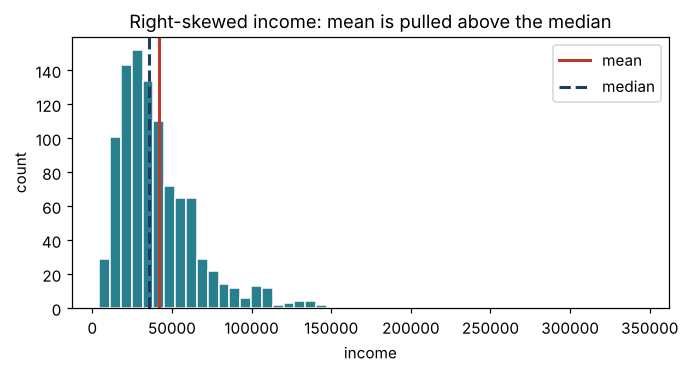

In [12]:
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
income = rng.lognormal(mean=10.5, sigma=0.6, size=1000)

q1, q3 = np.percentile(income, [25, 75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = int((income > upper).sum())

print(f"mean     : {income.mean():,.0f}")
print(f"median   : {np.median(income):,.0f}")
print(f"skewness : {stats.skew(income):.2f}")
print(f"IQR      : {iqr:,.0f}   upper fence: {upper:,.0f}   outliers: {outliers}")
assert income.mean() > np.median(income)       # right skew: mean > median

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(income, bins=50, color="#2A7F8E", edgecolor="white")
ax.axvline(income.mean(), color="#C0392B", lw=2, label="mean")
ax.axvline(np.median(income), color="#1F3A5F", lw=2, ls="--", label="median")
ax.set_title("Right-skewed income: mean is pulled above the median")
ax.set_xlabel("income"); ax.set_ylabel("count"); ax.legend()
plt.show()

**Task 4.2** Correlation and simple linear regression between study hours and exam score.

correlation r : 0.935
slope         : 5.18 points per extra hour
intercept     : 39.82
R-squared     : 0.874


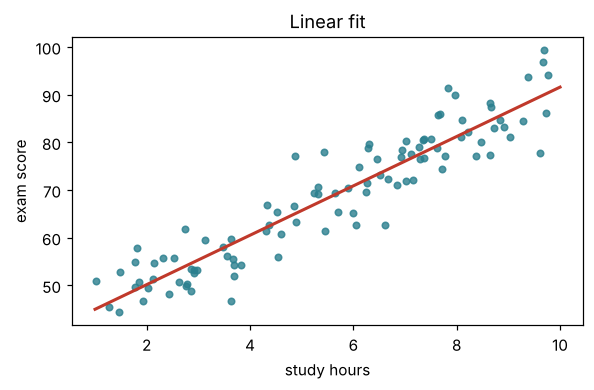

In [13]:
rng = np.random.default_rng(3)
hours = rng.uniform(1, 10, 100)
score = 40 + 5 * hours + rng.normal(0, 5, 100)

r = np.corrcoef(hours, score)[0, 1]
res = stats.linregress(hours, score)
print(f"correlation r : {r:.3f}")
print(f"slope         : {res.slope:.2f} points per extra hour")
print(f"intercept     : {res.intercept:.2f}")
print(f"R-squared     : {res.rvalue ** 2:.3f}")
assert r > 0.8 and 4 < res.slope < 6

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(hours, score, s=18, color="#2A7F8E", alpha=0.8)
xs = np.array([1, 10])
ax.plot(xs, res.intercept + res.slope * xs, color="#C0392B", lw=2)
ax.set_xlabel("study hours"); ax.set_ylabel("exam score"); ax.set_title("Linear fit")
plt.show()

**Task 4.3** Bayes' theorem. A disease has 1% prevalence. A test has 95% sensitivity and 90% specificity. What is the probability of having the disease given a positive test? Verify by simulation.

In [14]:
prevalence, sensitivity, specificity = 0.01, 0.95, 0.90

p_positive = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
posterior = sensitivity * prevalence / p_positive
print(f"P(disease | positive) by Bayes     : {posterior:.4f}")

rng = np.random.default_rng(11)
N = 1_000_000
disease = rng.random(N) < prevalence
positive = np.where(disease, rng.random(N) < sensitivity, rng.random(N) < (1 - specificity))
simulated = disease[positive].mean()
print(f"P(disease | positive) by simulation: {simulated:.4f}")
assert abs(simulated - posterior) < 0.01
print("Even with a good test, most positives are false alarms because the disease is rare.")

P(disease | positive) by Bayes     : 0.0876
P(disease | positive) by simulation: 0.0881
Even with a good test, most positives are false alarms because the disease is rare.


**Task 4.4** Work with common distributions: binomial, normal (68-95-99.7 rule) and Poisson.

In [15]:
p6 = stats.binom.pmf(6, 10, 0.5)          # exactly 6 heads in 10 flips
p8 = stats.binom.sf(7, 10, 0.5)           # at least 8 heads
print(f"Binomial: P(exactly 6 heads) = {p6:.4f},  P(at least 8 heads) = {p8:.4f}")

for k in (1, 2, 3):
    inside = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"Normal  : within {k} std dev = {inside:.4f}")

print(f"Poisson : P(7 or more calls) when the mean is 4/hour = {stats.poisson.sf(6, 4):.4f}")

assert abs(p6 - 210 / 1024) < 1e-12 and abs(p8 - 56 / 1024) < 1e-12

Binomial: P(exactly 6 heads) = 0.2051,  P(at least 8 heads) = 0.0547
Normal  : within 1 std dev = 0.6827
Normal  : within 2 std dev = 0.9545
Normal  : within 3 std dev = 0.9973
Poisson : P(7 or more calls) when the mean is 4/hour = 0.1107


**Task 4.5** Demonstrate the Central Limit Theorem: sample means from a skewed (exponential) population become normal as the sample size grows.

population skewness: 1.99
n= 2: skewness of sample means = 1.49
n=30: skewness of sample means = 0.36
std of means (n=30): 0.367   theory sigma/sqrt(n): 0.363


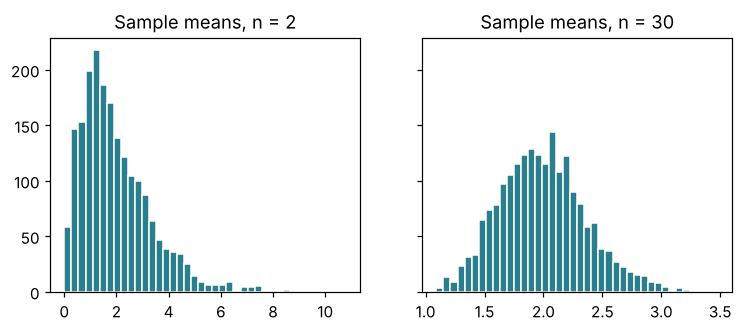

In [16]:
rng = np.random.default_rng(5)
population = rng.exponential(scale=2.0, size=100_000)
print(f"population skewness: {stats.skew(population):.2f}")

means = {n: np.array([rng.choice(population, n).mean() for _ in range(2000)]) for n in (2, 30)}
for n, m in means.items():
    print(f"n={n:>2}: skewness of sample means = {stats.skew(m):.2f}")

expected_se = population.std() / np.sqrt(30)
print(f"std of means (n=30): {means[30].std():.3f}   theory sigma/sqrt(n): {expected_se:.3f}")
assert stats.skew(means[30]) < stats.skew(means[2])
assert abs(means[30].std() - expected_se) / expected_se < 0.05

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, n in zip(axes, (2, 30)):
    ax.hist(means[n], bins=40, color="#2A7F8E", edgecolor="white")
    ax.set_title(f"Sample means, n = {n}")
plt.show()

**Task 4.6** Hypothesis testing. Compare a treatment group with a control group using a Welch t-test, report a confidence interval, test a categorical association with chi-square, and confirm the Type I error rate by simulation.

In [17]:
rng = np.random.default_rng(21)
control = rng.normal(100, 15, 60)
treatment = rng.normal(108, 15, 60)

res = stats.ttest_ind(treatment, control, equal_var=False)
ci = res.confidence_interval(0.95)
diff = treatment.mean() - control.mean()
print(f"mean difference = {diff:.2f}")
print(f"t = {res.statistic:.2f}, p = {res.pvalue:.4f}")
print(f"95% CI for the difference: ({ci.low:.2f}, {ci.high:.2f})")
print("Decision at alpha = 0.05:", "reject H0" if res.pvalue < 0.05 else "fail to reject H0")

table = np.array([[30, 70],     # ad version A: converted / not converted
                  [45, 55]])    # ad version B
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"\nChi-square = {chi2:.2f}, dof = {dof}, p = {p:.4f}")

false_positives = np.mean([
    stats.ttest_ind(rng.normal(0, 1, 30), rng.normal(0, 1, 30)).pvalue < 0.05
    for _ in range(2000)
])
print(f"\nA/A tests with p < 0.05 (should be near 5%): {false_positives:.1%}")
assert 0.03 < false_positives < 0.07

mean difference = 6.82
t = 2.65, p = 0.0092
95% CI for the difference: (1.72, 11.91)
Decision at alpha = 0.05: reject H0

Chi-square = 4.18, dof = 1, p = 0.0409

A/A tests with p < 0.05 (should be near 5%): 4.7%


## Assignment 5 - Industry best practices
**Task 5.1** Reproducible, stratified train/test split on an imbalanced classification dataset.

In [18]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

SEED = 42
X, y = make_classification(n_samples=2000, n_features=10, n_informative=5,
                           weights=[0.9, 0.1], random_state=SEED)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

print("train/test shapes:", Xtr.shape, Xte.shape)
print(f"positive rate -> all: {y.mean():.3f}  train: {ytr.mean():.3f}  test: {yte.mean():.3f}")
assert abs(ytr.mean() - yte.mean()) < 0.01     # stratification keeps class balance

train/test shapes: (1500, 10) (500, 10)
positive rate -> all: 0.103  train: 0.103  test: 0.104


**Task 5.2** Always start with a baseline. Compare a "predict the majority class" baseline with a logistic regression pipeline (with balanced class weights) and show why accuracy alone misleads on imbalanced data.

In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

baseline = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
pipe = Pipeline([("scale", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(Xtr, ytr)

def evaluate(model):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {
        "accuracy":  accuracy_score(yte, pred),
        "precision": precision_score(yte, pred, zero_division=0),
        "recall":    recall_score(yte, pred),
        "f1":        f1_score(yte, pred),
        "roc_auc":   roc_auc_score(yte, proba),
    }

results = pd.DataFrame({"baseline": evaluate(baseline), "logistic_regression": evaluate(pipe)}).T.round(3)
print(results)
print("\nConfusion matrix (rows = actual, cols = predicted):")
print(confusion_matrix(yte, pipe.predict(Xte)))

assert results.loc["baseline", "recall"] == 0          # baseline never finds a positive
assert results.loc["logistic_regression", "recall"] > 0.4
assert results.loc["logistic_regression", "roc_auc"] > 0.7
print("\nThe baseline scores high accuracy while finding no positives; recall, F1 and ROC-AUC expose that.")
print("class_weight='balanced' makes the model pay more attention to the rare class.")

                     accuracy  precision  recall     f1  roc_auc
baseline                0.896       0.00    0.00  0.000    0.500
logistic_regression     0.740       0.25    0.75  0.375    0.824

Confusion matrix (rows = actual, cols = predicted):
[[331 117]
 [ 13  39]]

The baseline scores high accuracy while finding no positives; recall, F1 and ROC-AUC expose that.
class_weight='balanced' makes the model pay more attention to the rare class.


**Task 5.3** Use stratified cross-validation to estimate performance and its variability, instead of trusting a single split.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, Xtr, ytr, cv=cv, scoring="f1")
print("F1 per fold :", scores.round(3))
print(f"mean +/- std: {scores.mean():.3f} +/- {scores.std():.3f}")
assert len(scores) == 5

F1 per fold : [0.388 0.43  0.397 0.394 0.397]
mean +/- std: 0.401 +/- 0.015


**Task 5.4** Data leakage. The labels below are pure noise, so honest accuracy should be about 50%. Selecting features on the full dataset before cross-validation leaks the answer; doing it inside a pipeline does not.

In [21]:
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))          # 1000 random features
yn = rng.integers(0, 2, 100)               # random labels - nothing to learn
cv = StratifiedKFold(5, shuffle=True, random_state=0)

leaky_X = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)     # WRONG: uses all labels
acc_leaky = cross_val_score(LogisticRegression(max_iter=1000), leaky_X, yn, cv=cv).mean()

safe = Pipeline([("select", SelectKBest(f_classif, k=20)),       # RIGHT: fitted per training fold
                 ("clf", LogisticRegression(max_iter=1000))])
acc_safe = cross_val_score(safe, Xn, yn, cv=cv).mean()

print(f"leaky accuracy (looks great, is fake): {acc_leaky:.2f}")
print(f"safe accuracy  (honest, about chance): {acc_safe:.2f}")
assert acc_leaky > acc_safe + 0.1

leaky accuracy (looks great, is fake): 0.85
safe accuracy  (honest, about chance): 0.57


**Task 5.5** Data validation and an environment snapshot: two habits that make work trustworthy and reproducible.

In [22]:
def validate_sales(df):
    """Return a list of data-quality problems found in a sales table."""
    problems = []
    required = {"order_id", "region", "product", "quantity", "unit_price", "revenue"}
    missing = required - set(df.columns)
    if missing:
        return [f"missing columns: {sorted(missing)}"]
    if df.isna().any().any():
        problems.append("null values present")
    if (df[["quantity", "unit_price", "revenue"]] < 0).any().any():
        problems.append("negative values")
    if df["order_id"].duplicated().any():
        problems.append("duplicate order_id")
    return problems

bad = sales.assign(revenue=sales["quantity"] * sales["unit_price"])   # the uncleaned table
print("cleaned table :", validate_sales(sales_clean) or "no problems")
print("raw table     :", validate_sales(bad))
assert validate_sales(sales_clean) == []
assert len(validate_sales(bad)) == 2

import sys, scipy, sklearn
print("\nEnvironment snapshot")
print("python      :", sys.version.split()[0])
for lib in (np, pd, scipy, sklearn):
    print(f"{lib.__name__:<11} :", lib.__version__)

cleaned table : no problems
raw table     : ['null values present', 'duplicate order_id']

Environment snapshot
python      : 3.13.16
numpy       : 2.5.3
pandas      : 3.0.5
scipy       : 1.18.1
sklearn     : 1.9.1


## Summary of what was demonstrated
- **Python:** functions, collections, comprehensions, error handling, standard library use.
- **Data types:** statistical types and scales, correct pandas dtypes, safe conversion of messy input.
- **NumPy and pandas:** vectorised maths, cleaning, grouping, pivoting, merging.
- **Statistics:** descriptive measures, correlation, Bayes, distributions, the Central Limit Theorem, hypothesis tests, Type I error.
- **Best practices:** seeds, stratified splits, baselines, cross-validation, pipelines to prevent leakage, validation checks, environment records.